# Figure 3 — conservation-prioritized siting (CON) vs BAU

Tidied, path-migrated rewrite of `Fig-3.ipynb`. In the new `results/` layout the old
`uncertainty-analysis/…-MMM` files became a **scenario × β sweep, central DM-RM** case.
Per Fig-4's signpost map, **CON = scenario `BAU` at β = 0.60** (`BETA_CON`).

**Path migration (old → new):**

| old | new |
|---|---|
| `…/affected-species-range-2050-BAU-50km-MMM.tif` | `biodiversity-risk/affected-species-range-2050-BAU-B0.00-50km-DM-RM.tif` |
| `…/affected-species-range-2050-CON-50km-MMM.tif` | `biodiversity-risk/affected-species-range-2050-BAU-B0.60-50km-DM-RM.tif` |
| `…/allocated-extraction-2023-2050-BAU-50km-MMM.tif` | `extraction-rasters/allocated-extraction-2023-2050-BAU-B0.00-50km-DM-RM.tif` |
| `…/allocated-extraction-2023-2050-CON-50km-MMM.tif` | `extraction-rasters/allocated-extraction-2023-2050-BAU-B0.60-50km-DM-RM.tif` |
| `…/mining-area-expansion-2050-{BAU,CON}-50km-MMM.tif` | `mining-area/mining-area-expansion-2050-BAU-B{0.00,0.60}-50km-DM-RM.tif` |
| RWR, world-map, country-pseudo-values | unchanged |

**Notes:** capital-city markers in the zoom-ins use a local `data/ne_10m_populated_places/`
shapefile if present, otherwise the bundled Natural Earth `populated_places` is fetched via
cartopy (auto-download + cache). CON's old LLL/HHH uncertainty was not produced by the β-sweep
pipeline → that text line uses the point estimate.

In [ ]:
import os
from pathlib import Path
import string
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
import pyproj
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import FuncFormatter, FormatStrFormatter
import matplotlib.gridspec as gridspec
import seaborn as sns
from cartopy import feature as cf
from cartopy import crs as ccrs
import cartopy.io.shapereader as shpreader

In [ ]:
# ---------------------------------------------------------------------------
# CONFIG — paths + the two scenarios this figure compares.
# ---------------------------------------------------------------------------
ROOT    = Path('..')
DATA    = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'

RES      = '50km'
DR       = 'DM-RM'    # central demand/reserve case
AR       = 'M'
BETA_BAU = 0.00       # BAU  = scenario BAU at beta 0.00
BETA_CON = 0.60       # CON  = scenario BAU at beta 0.60 (conservation-siting knee)

def asr_tif(beta):
    return RESULTS / 'biodiversity-risk' / f'mining-biodiversity-overlap-2050-BAU-B{beta:.2f}-{RES}-{DR}-A{AR}.tif'
def mine_tif(beta):
    return RESULTS / 'mining-area' / f'mining-area-expansion-2050-BAU-B{beta:.2f}-{RES}-{DR}-A{AR}.tif'

ALLOC_BAU = RESULTS / 'extraction-rasters' / f'allocated-extraction-2023-2050-BAU-B{BETA_BAU:.2f}-{RES}-{DR}.tif'
ALLOC_CON = RESULTS / 'extraction-rasters' / f'allocated-extraction-2023-2050-BAU-B{BETA_CON:.2f}-{RES}-{DR}.tif'

COUNTRY_RASTER = RESULTS / 'country-rasters' / f'country-raster-eck4-{RES}.tif'
RWR_RASTER     = RESULTS / 'area-of-habitat-50km' / 'rarity-weighted-richness-vertebrates-50km.tif'
WORLD_MAP      = DATA / 'simplified-world-map' / 'world-map.shp'
# Capital-city markers (zoom-ins): a local Natural Earth copy if present, else
# fetched via cartopy in the next cell. Loaded below as `capitals`.
CAPITALS_SHP   = DATA / 'ne_10m_populated_places' / 'ne_10m_populated_places.shp'

In [ ]:
# --- vectors -------------------------------------------------------------
world_map      = gpd.read_file(WORLD_MAP)
world_map      = world_map.drop([31])
world_map_eck4 = world_map.to_crs('ESRI:54012')

# capital cities for the zoom-in markers: use a local Natural Earth copy if present,
# else fetch the bundled Natural Earth 'populated_places' via cartopy (auto-download + cache).
if CAPITALS_SHP.exists():
    populated_places = gpd.read_file(CAPITALS_SHP)
else:
    populated_places = gpd.read_file(
        shpreader.natural_earth(resolution='10m', category='cultural', name='populated_places'))
capitals = populated_places[populated_places['FEATURECLA'] == 'Admin-0 capital'].to_crs('ESRI:54012')
CAPITALS_AVAILABLE = len(capitals) > 0
print(f'capitals: {len(capitals)} Admin-0 capitals loaded')

country_pseudo_values = pd.read_csv(DATA / 'country-pseudo-values.csv')
country_raster_50km_  = rio.open(COUNTRY_RASTER)
country_raster_50km   = country_raster_50km_.read(1)

capitals: 202 Admin-0 capitals loaded


In [ ]:
# --- rasters: BAU vs CON (= BAU at beta 0.60) ----------------------------
mining_biodiversity_overlap_BAU = rio.open(asr_tif(BETA_BAU)).read(1)
mining_biodiversity_overlap_CON = rio.open(asr_tif(BETA_CON)).read(1)

allocated_extraction_BAU   = rio.open(ALLOC_BAU).read(1)
allocated_extraction_CON   = rio.open(ALLOC_CON).read(1)

mining_area_expansion_BAU  = rio.open(mine_tif(BETA_BAU)).read(1)
mining_area_expansion_CON  = rio.open(mine_tif(BETA_CON)).read(1)

rarity_weighted_richness_50km = rio.open(RWR_RASTER).read(1)

overlap_change_CON        = mining_biodiversity_overlap_BAU - mining_biodiversity_overlap_CON
extraction_change_CON = allocated_extraction_BAU - allocated_extraction_CON

print('BAU vs CON allocated extraction (sum):', np.sum(allocated_extraction_BAU), np.sum(allocated_extraction_CON))

BAU vs CON allocated extraction (sum): 446430.2561383927 446430.2561383928


In [ ]:
# --- shared drawing helpers ---------------------------------------------
def draw_the_background(axx):
    nodata_area = world_map_eck4[world_map_eck4['GID_0'].isin(['CAF', 'SSD', 'ESH', 'SWZ', 'LSO', 'GRL'])]
    world_map_eck4.plot(color='whitesmoke', edgecolor='k', lw=0.0, ax=axx, zorder=0)
    world_map_eck4.plot(color='none', edgecolor='lightgrey', lw=0.3, ax=axx, zorder=10)
    nodata_area.plot(hatch='////', linewidth=0.5, color='none', edgecolor='grey', zorder=15, ax=axx)
    axx.set_ylim(-6.6e6, 8.6e6)
    axx.axis('off')
    cax1 = axx.inset_axes([0.43, -0.1, 0.02, 0.03])
    cax1.add_patch(Rectangle((0, 0), 1, 1, facecolor='white', edgecolor='grey', hatch='////'))
    cax1.axis('off')
    cax1.text(0.0, -3.0, 'No\ndata', fontsize=9)

display_extent_50km = [country_raster_50km_.bounds.left, country_raster_50km_.bounds.right,
                       country_raster_50km_.bounds.bottom, country_raster_50km_.bounds.top]
norm_ASR_change = BoundaryNorm([-0.05, -0.01, -1e-3, 0, 1e-3, 0.01, 0.05], 256)

In [ ]:
# --- zoom-in helpers (capital markers skipped when unavailable) ----------
def _lonlat_to_eck4(lon, lat, src):
    proj = pyproj.Transformer.from_crs("EPSG:4326", src.crs.to_string(), always_xy=True)
    x, y = proj.transform(lon, lat)
    col, row = ~src.transform * (x, y)
    return int(row), int(col)

def _compute_extent(r1, r2, c1, c2, transform):
    x_ul = transform.c + c1 * transform.a
    y_ul = transform.f + r1 * transform.e
    x_lr = transform.c + c2 * transform.a
    y_lr = transform.f + r2 * transform.e
    return (x_ul, x_lr, y_lr, y_ul)

def _eck4_to_lonlat(x, y):
    proj_to_lonlat = pyproj.Transformer.from_crs("ESRI:54012", "EPSG:4326", always_xy=True)
    return proj_to_lonlat.transform(x, y)

def _fmt_lon(lon):
    return f"{abs(lon):.1f}°E" if lon >= 0 else f"{abs(lon):.1f}°W"
def _fmt_lat(lat):
    return f"{abs(lat):.1f}°N" if lat >= 0 else f"{abs(lat):.1f}°S"

def _capitals_in(xmin, xmax, ymin, ymax):
    if not CAPITALS_AVAILABLE:
        return None
    return capitals[(capitals.geometry.x >= xmin) & (capitals.geometry.x <= xmax) &
                    (capitals.geometry.y >= ymin) & (capitals.geometry.y <= ymax)]

def display_a_zoomin(lon, lat, axx, data=None, cmap='RdYlBu', the_norm=None, star=40, nticks=2):
    if data is None:
        data = overlap_change_CON
    if the_norm is None:
        the_norm = norm_ASR_change
    center_i, center_j = _lonlat_to_eck4(lon, lat, country_raster_50km_)
    r = 10
    slice_1 = data[center_i-r:center_i+r, center_j-r:center_j+r]
    display_extent = _compute_extent(center_i-r, center_i+r, center_j-r, center_j+r, country_raster_50km_.transform)
    xmin, xmax, ymin, ymax = display_extent
    cap = _capitals_in(xmin, xmax, ymin, ymax)
    axx.add_feature(cf.COASTLINE, linewidth=1.0)
    axx.add_feature(cf.BORDERS, linewidth=0.8, edgecolor='grey', zorder=10)
    if cap is not None and len(cap):
        axx.scatter(cap.geometry.x, cap.geometry.y, marker='*', s=star, lw=0.7,
                    edgecolor='k', facecolor='yellow', alpha=1.0, transform=ccrs.EckertIV(), zorder=20)
    gg = axx.imshow(np.where(slice_1 == 0, np.nan, slice_1), cmap=cmap, interpolation='nearest',
                    norm=the_norm, origin='upper', extent=display_extent, zorder=0, alpha=1.0)
    xticks = np.linspace(display_extent[0], display_extent[1], nticks)
    yticks = np.linspace(display_extent[2], display_extent[3], nticks)
    axx.set_xticks(xticks); axx.set_yticks(yticks)
    axx.set_xticklabels([_fmt_lon(_eck4_to_lonlat(aa, display_extent[2])[0]) for aa in xticks], fontsize=7)
    axx.set_yticklabels([_fmt_lat(_eck4_to_lonlat(display_extent[0], aa)[1]) for aa in yticks], fontsize=7)
    return display_extent if data is overlap_change_CON else gg

def add_rectangle(display_extent, main_ax, sub_ax, corners_main=[1, 2], corners_sub=[3, 4]):
    x0, x1, y0, y1 = display_extent
    rect = Rectangle((x0, y0), x1-x0, y1-y0, linewidth=0.75, edgecolor='k', facecolor='none',
                     transform=ccrs.EckertIV(), zorder=20)
    main_ax.add_patch(rect)
    corners = {1: (x0, y0), 2: (x0, y1), 3: (x1, y0), 4: (x1, y1)}
    sel_m = [corners[i] for i in corners_main]
    sel_s = [corners[i] for i in corners_sub]
    main_ax.add_artist(ConnectionPatch(xyA=sel_m[0], coordsA=main_ax.transData, xyB=sel_s[0], coordsB=sub_ax.transData, color='k', linewidth=0.75, zorder=30))
    main_ax.add_artist(ConnectionPatch(xyA=sel_m[1], coordsA=main_ax.transData, xyB=sel_s[1], coordsB=sub_ax.transData, color='k', linewidth=0.75, zorder=30))

In [ ]:
# --- ASR waterfall components (global) ----------------------------------
total_BAU   = np.sum(mining_biodiversity_overlap_BAU)
total_CON   = np.sum(mining_biodiversity_overlap_CON)
reduction_1 = np.sum(np.where(overlap_change_CON >= 0.01, overlap_change_CON, 0))
reduction_2 = np.sum(np.where((overlap_change_CON > 0.001) & (overlap_change_CON < 0.01), overlap_change_CON, 0))
reduction_3 = np.sum(np.where((overlap_change_CON > 0.000) & (overlap_change_CON < 0.001), overlap_change_CON, 0))
increase_1  = -np.sum(np.where((overlap_change_CON >= -0.001) & (overlap_change_CON < 0.000), overlap_change_CON, 0))
increase_2  = -np.sum(np.where((overlap_change_CON >= -0.01)  & (overlap_change_CON < -0.001), overlap_change_CON, 0))
increase_3  = -np.sum(np.where(overlap_change_CON < -0.01, overlap_change_CON, 0))

In [ ]:
# --- panels a & b inputs: the phi=0 (no-CE) conservation-siting frontier across beta -----
# Built from the two DM-RM summary tables (scenario 'BAU' rows; volume is constant at
# alloc_bau across beta, so beta only changes WHERE mining happens). CON sits at the
# beta_CON knee (= BETA_CON).
#   panel a -> transport-WORK cost of raising beta (work increase vs BAU.b0)
#   panel b -> cost-benefit FRONTIER ($/t increase vs absolute overlap reduction)
#              [moved from Fig-4's Extended-Data-Figure-6 panel a]
_cost = pd.read_csv(RESULTS / 'extraction-rasters' / f'cost-analysis-{DR}.csv')
_risk = pd.read_csv(RESULTS / 'biodiversity-risk' / f'biodiversity-risk-summary-{DR}.csv')
_df   = _cost.merge(_risk, on=['scenario', 'beta'])

_b0 = _df[(_df.scenario == 'BAU') & (_df.beta == 0.0)].iloc[0]               # global baseline (BAU, beta=0)
_alloc_bau, _cost_bau, _asr_bau = _b0['alloc_Gt'], _b0['cost_Tusd_central'], _b0['overlap']
_work_bau = _b0['work_Gt_km']

_s = _df[_df.scenario == 'BAU'].sort_values('beta').reset_index(drop=True)   # phi=0 frontier (beta 0 -> 1)
frontier_beta = _s['beta'].values
frontier_cost = (_s['cost_Tusd_central'].values / _s['alloc_Gt'].values
                 - _cost_bau / _alloc_bau) * 1000.0                          # per-tonne cost increase vs BAU.b0 ($/t)
frontier_red  = _asr_bau - _s['overlap'].values                             # absolute overlap reduction (species-range eq.)
frontier_ic   = int(np.where(np.isclose(frontier_beta, BETA_CON))[0][0])    # beta_CON knee index

# transport-work increase vs BAU.b0 as beta rises (panel a). Volume is constant across beta,
# so the % increase here equals the % increase in TOTAL transport cost (cost is proportional to work).
frontier_work_pct = 100.0 * (_s['work_Gt_km'].values / _work_bau - 1.0)      # % increase vs BAU.b0 (reader-friendly)
frontier_work_abs = (_s['work_Gt_km'].values - _work_bau) / 1000.0          # Tt-km increase (physical; no $ assumption)

BETA_CMAP = 'viridis'   # colour scale encoding beta along panel b's frontier (swap to 'plasma'/'Blues' to taste)

def draw_transport_work(ax, mode='pct'):
    """Panel a: transport-work increase vs BAU as conservation priority beta rises (phi=0 frontier).
    mode='pct' -> % increase (== total transport-cost %); mode='abs' -> trillion tonne-km (physical)."""
    BLU, GRN = '#2b8cbe', 'lightgreen'
    b, ic = frontier_beta, frontier_ic
    y = frontier_work_pct if mode == 'pct' else frontier_work_abs
    ax.axvspan(b[0], b[ic], color=BLU, alpha=0.06, zorder=0)                # at-or-below-knee band (beta <= beta_CON)
    ax.plot(b, y, '-', color=BLU, lw=1.4, zorder=3)
    ax.scatter(b, y, s=16, color=BLU, ec='k', lw=0.4, zorder=4, clip_on=False)
    ax.scatter(0, 0, s=30, color='none', ec='k', lw=1.3, zorder=5, clip_on=False)
    ax.scatter(1, y[-1], s=30, color='none', ec='k', lw=1.3, zorder=5, clip_on=False)
    ax.plot(b[ic], y[ic], marker='^', mfc=GRN, mec='k', mew=1.0, ms=8, zorder=5)
    ax.annotate('CON', (b[ic]+0.01, y[ic]-50), textcoords='offset points', color='g',
                xytext=(6, 1), ha='left', va='bottom', fontsize=8, fontweight='semibold')
    ax.annotate('BAU', (b[0], y[0]), textcoords='offset points', xytext=(5, 5), fontsize=8, fontweight='semibold')
    ax.annotate('Biodiversity-first', (b[-1], y[-1]), textcoords='offset points', color='k',
                xytext=(-8, -2), ha='right', va='top', fontsize=8, fontweight='semibold')
    ax.set_xlabel('Conservation priority β', fontsize=9)
    ax.set_ylabel('Transport-work increase (%)' if mode == 'pct'
                  else 'Transport-work increase (Tt·km)', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set(xlim=(0, 1), ylim=(0, 600))
    ax.grid(alpha=0.25, lw=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

def draw_cost_benefit_frontier(ax):
    """Panel b (Fig-4 ED panel a): $/t increase vs absolute overlap reduction.
    The frontier line + points are coloured by beta (the implicit parameter along the curve);
    CON triangle sits at the knee. A compact beta colour key goes in the lower-right."""
    from matplotlib.collections import LineCollection
    GRN = 'lightgreen'
    x, y, b, ic = frontier_cost, frontier_red, frontier_beta, frontier_ic
    norm = plt.Normalize(0, 1)
    ax.axvspan(x[0], x[ic], color='#2b8cbe', alpha=0.06, zorder=0)         # cheaper-than-knee band
    # frontier line, coloured per-segment by beta
    pts  = np.array([x, y]).T.reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = LineCollection(segs, cmap=BETA_CMAP, norm=norm, lw=1.8, zorder=3)
    lc.set_array(0.5 * (b[:-1] + b[1:]))                                   # segment colour = midpoint beta
    ax.add_collection(lc)
    ax.scatter(x, y, c=b, cmap=BETA_CMAP, norm=norm, s=16, ec='k', lw=0.4, zorder=4, clip_on=False)
    # signpost overlays on top
    ax.scatter(0, 0, s=25, color='none', ec='k', lw=1.0, zorder=5, clip_on=False)
    ax.scatter(x[-1], y[-1], s=30, color='none', ec='k', lw=1.0, zorder=5, clip_on=False)
    ax.plot(x[ic], y[ic], marker='^', mfc=GRN, mec='k', mew=1.0, ms=8, zorder=6)
    ax.annotate(f'CON (β = {BETA_CON:g})', (x[ic], y[ic]), textcoords='offset points', color='g',
                xytext=(7, -2), ha='left', va='top', fontsize=7, fontweight='semibold')
    ax.annotate('BAU (β = 0)', (x[0], y[0]), textcoords='offset points', xytext=(5, 3), fontsize=8, fontweight='semibold')
    ax.annotate('Biodiversity-first (β = 1)', (x[-1], y[-1]), textcoords='offset points', xytext=(-5, 6), ha='right', color='k', fontsize=8, fontweight='semibold')
    ax.set_xlabel('Transport-cost increase ($/t)', fontsize=9)
    ax.set_ylabel('Mining-biodiversity overlap reduction\n(Species-range equivalents)', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.set(xlim=(0, 16), ylim=(0, 2))
    ax.grid(alpha=0.25, lw=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    # beta colour key (compact; lower-right, where the curve has plateaued)
    sm = plt.cm.ScalarMappable(cmap=BETA_CMAP, norm=norm); sm.set_array([])
    cax = ax.inset_axes([0.60, 0.18, 0.33, 0.05])
    cb = ax.figure.colorbar(sm, cax=cax, orientation='horizontal', ticks=[0, 0.5, 1])
    cb.ax.tick_params(labelsize=6, length=2, pad=1)
    cb.set_label('Conservation priority β', fontsize=6.5, labelpad=2)
    cb.outline.set_linewidth(0.4)

print(f'frontier: {len(frontier_beta)} betas; CON (beta={BETA_CON:g}) at +${frontier_cost[frontier_ic]:.2f}/t, '
      f'{frontier_red[frontier_ic]:.2f} sp-range eq. reduction (BAU overlap={_asr_bau:.2f})')
print(f'transport work at CON: +{frontier_work_pct[frontier_ic]:.0f}% (+{frontier_work_abs[frontier_ic]:.1f} Tt-km) ; '
      f'at beta=1: +{frontier_work_pct[-1]:.0f}% (+{frontier_work_abs[-1]:.1f} Tt-km)')

frontier: 13 betas; CON (beta=0.6) at +$2.51/t, 1.33 sp-range eq. reduction (BAU overlap=2.64)
transport work at CON: +97% (+9.3 Tt-km) ; at beta=1: +595% (+57.3 Tt-km)


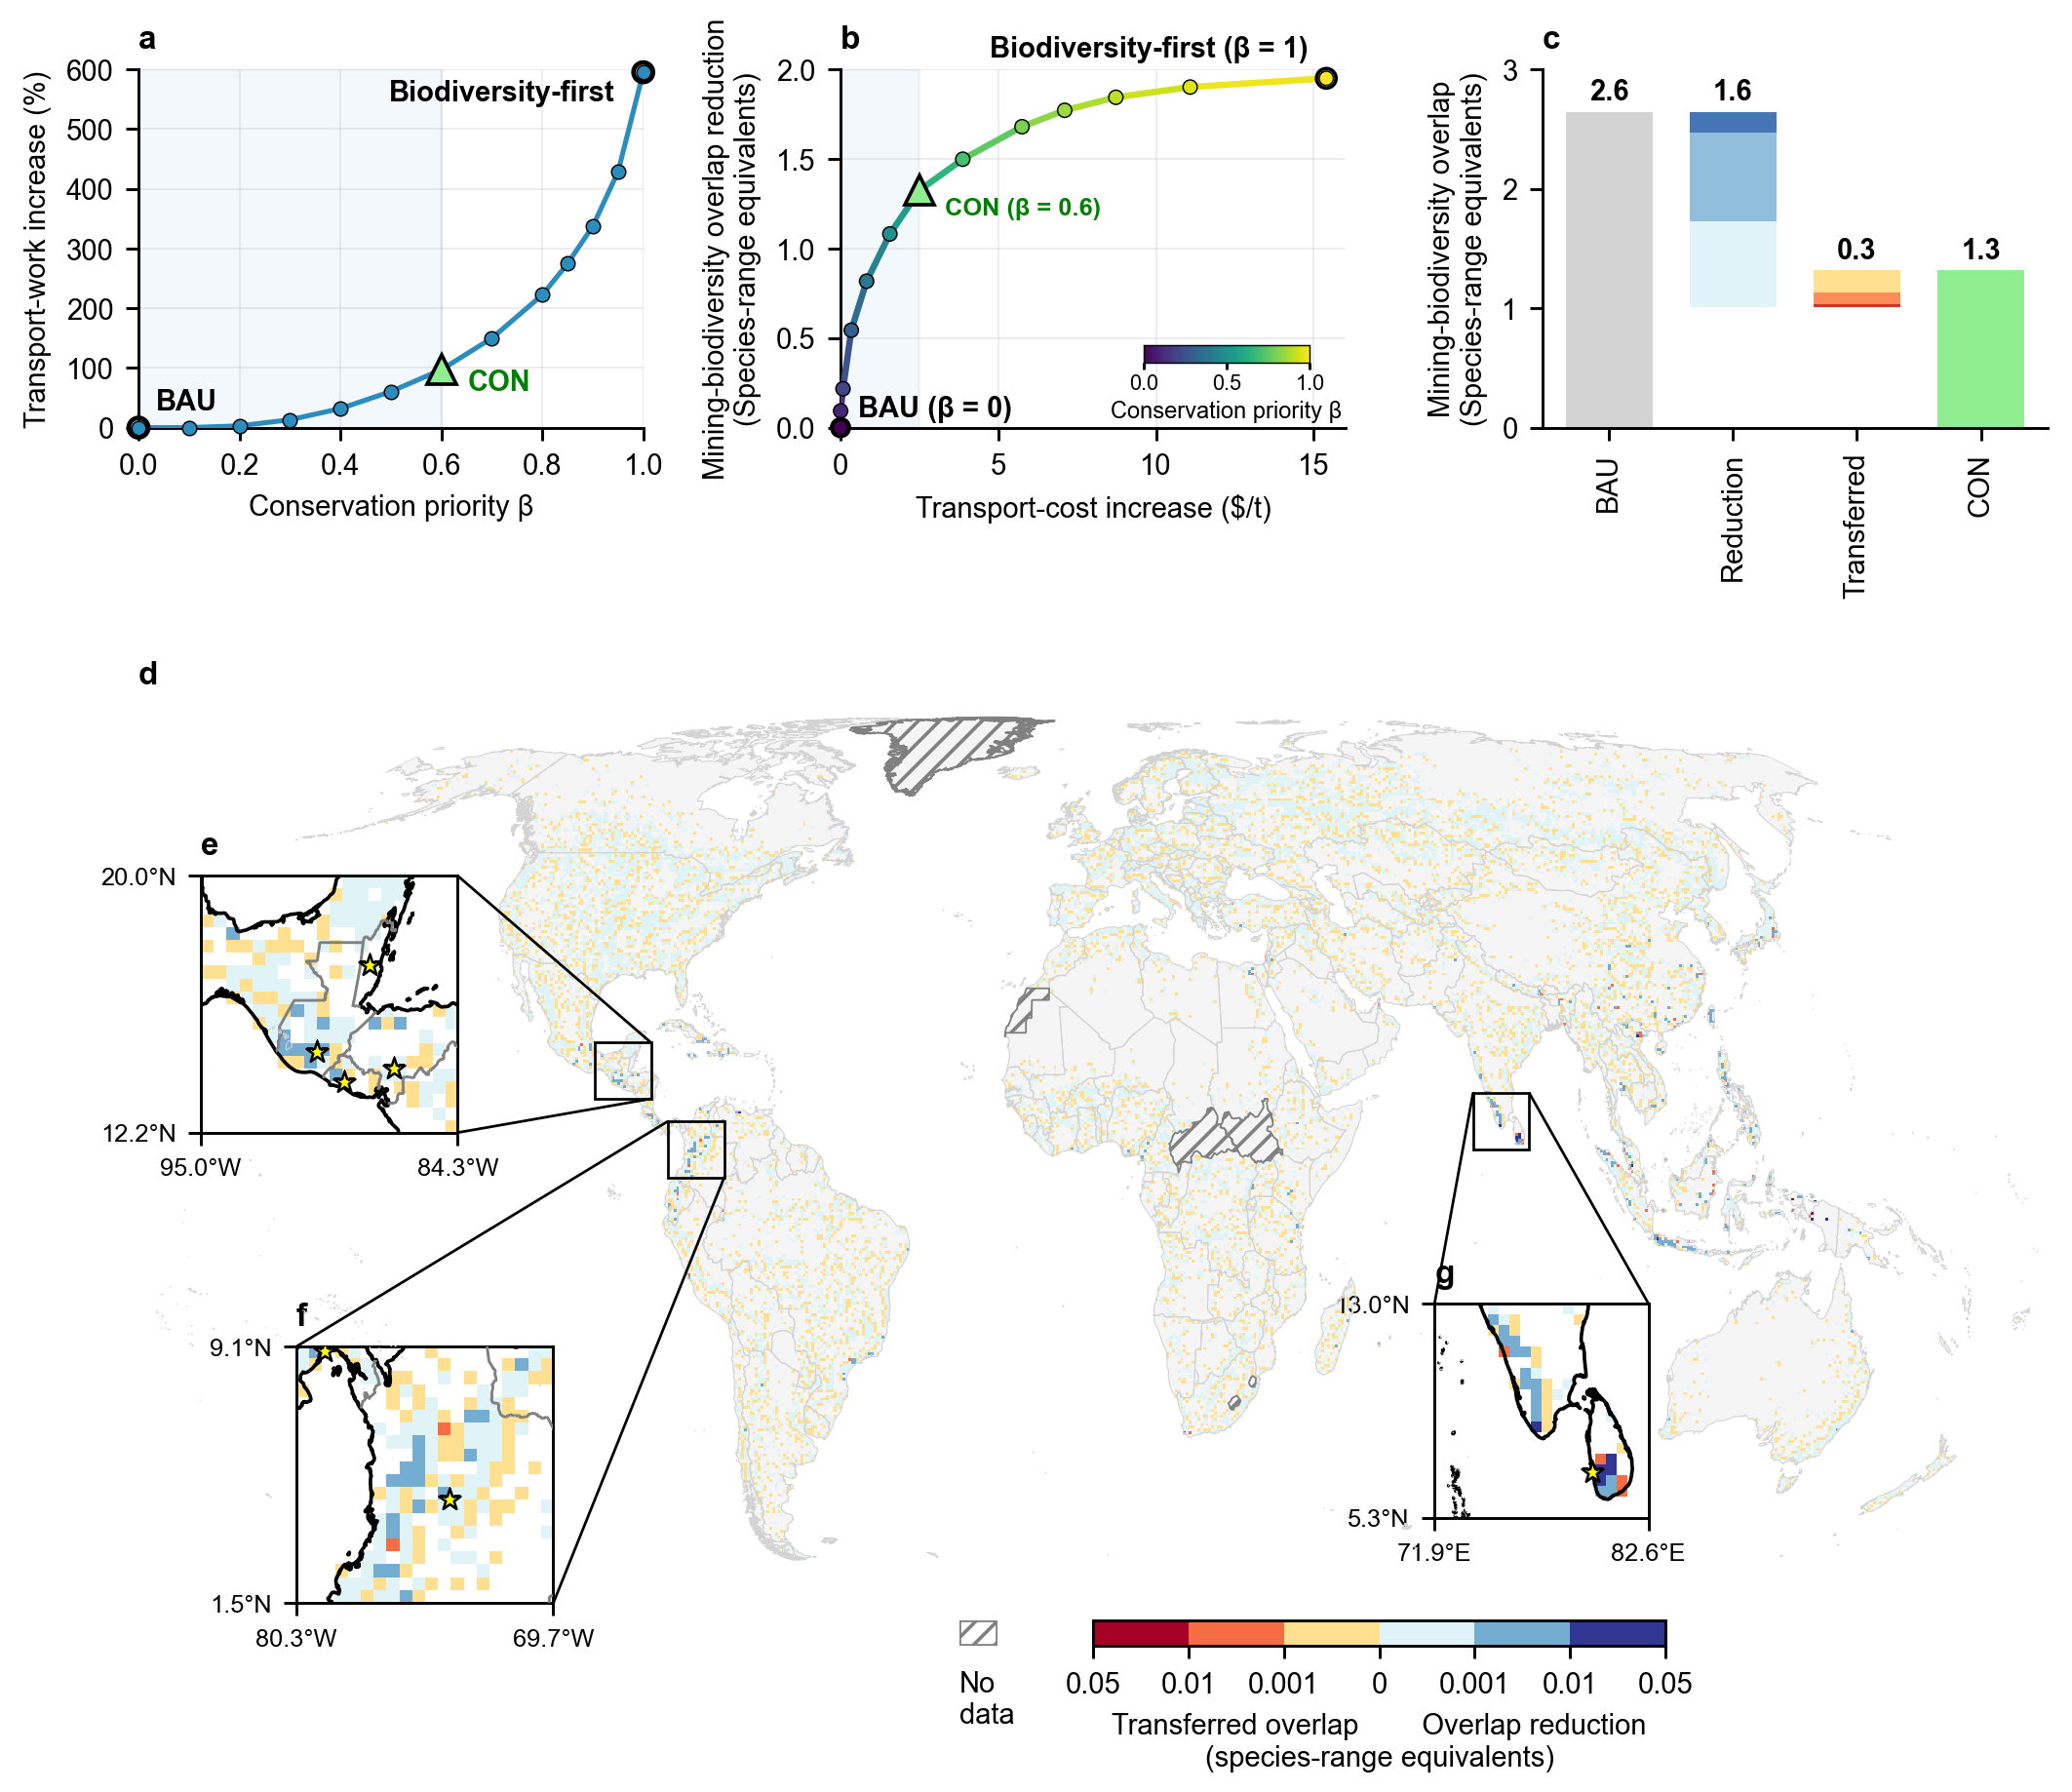

In [ ]:
# ===================== Figure 3 (main): Mining-biodiversity overlap change map + waterfall =========
fig = plt.figure(figsize=(8, 8), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

# --- a row of 3 result panels above the map ------------------------------
# 3-row grid: [top result panels] / [world map, spans 3 cols] / [empty row =
# breathing room for the colorbar inset that hangs below the map].
#   a = transport-work cost of conservation siting (work increase vs BAU, % vs β)
#   b = cost-benefit frontier (moved from Fig-4's ED figure, panel a)
#   c = mining-biodiversity overlap waterfall (ax1_4, drawn below)
gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 2.6, 0.7])
ax_top_f = fig.add_subplot(gs[0, 0])
ax_top_g = fig.add_subplot(gs[0, 1])
ax_top_h = fig.add_subplot(gs[0, 2])
for ax_t, lbl in zip((ax_top_f, ax_top_g, ax_top_h), ('a', 'b', 'c')):
    ax_t.set_title(lbl, loc='left', fontdict={'size': 12, 'weight': 'semibold'})

draw_transport_work(ax_top_f, mode='pct')               # panel a (top-left): work increase vs BAU (%)
draw_cost_benefit_frontier(ax_top_g)                    # panel b

ax1 = fig.add_subplot(gs[1, :], projection=ccrs.EckertIV())
draw_the_background(ax1)
im1 = ax1.imshow(np.where(overlap_change_CON == 0, np.nan, overlap_change_CON), cmap='RdYlBu',
                 interpolation='nearest', norm=norm_ASR_change, origin='upper', extent=display_extent_50km, zorder=5)
cax1 = ax1.inset_axes([0.50, -.1, 0.30, 0.03])
cbar1 = fig.colorbar(im1, cax=cax1, orientation='horizontal', label='Transferred overlap        Overlap reduction\n(species-range equivalents)')
formatter = FuncFormatter(lambda x, _: f'{x:.2g}')
cbar1.ax.xaxis.set_major_formatter(formatter); cbar1.formatter = formatter; cbar1.update_ticks()
cax1.set_xticklabels(['0.05', '0.01', '0.001', 0, 0.001, 0.01, 0.05])
ax1.set_title('d', loc='left', fontdict={'size': 12, 'weight': 'semibold'})

ax1_1 = ax1.inset_axes([0.00, 0.50, 0.20, 0.30], projection=ccrs.EckertIV())
ext1 = display_a_zoomin(-90, 16, ax1_1)
add_rectangle(ext1, ax1, ax1_1, [3, 4], [3, 4]); ax1_1.set_title('e', loc='left', fontdict={'size': 12, 'weight': 'semibold'})

ax1_2 = ax1.inset_axes([0.05, -0.05, 0.20, 0.30], projection=ccrs.EckertIV())
ext2 = display_a_zoomin(-75, 5, ax1_2)
add_rectangle(ext2, ax1, ax1_2, [2, 3], [2, 3]); ax1_2.set_title('f', loc='left', fontdict={'size': 12, 'weight': 'semibold'})

ax1_3 = ax1.inset_axes([0.65, 0.05, 0.17, 0.25], projection=ccrs.EckertIV())
ext3 = display_a_zoomin(78, 9, ax1_3)
add_rectangle(ext3, ax1, ax1_3, [2, 4], [2, 4]); ax1_3.set_title('g', loc='left', fontdict={'size': 12, 'weight': 'semibold'})

# ax1_4 = ax1.inset_axes([0.05, -0.12, 0.20, 0.4], zorder=10)
ax1_4 = ax_top_h
w = 0.7
ax1_4.bar(0, total_BAU, color='lightgrey', width=w)
ax1_4.bar(1, reduction_1, bottom=total_BAU - reduction_1, color='#4575b4', width=w)
ax1_4.bar(1, reduction_2, bottom=total_BAU - reduction_1 - reduction_2, color='#91bfdb', width=w)
ax1_4.bar(1, reduction_3, bottom=total_BAU - reduction_1 - reduction_2 - reduction_3, color='#e0f3f8', width=w)
ax1_4.bar(2, increase_1, bottom=total_CON - increase_1, color='#fee090', width=w)
ax1_4.bar(2, increase_2, bottom=total_CON - increase_1 - increase_2, color='#fc8d59', width=w)
ax1_4.bar(2, increase_3, bottom=total_CON - increase_1 - increase_2 - increase_3, color='#d73027', width=w)
ax1_4.bar(3, total_CON, color='lightgreen', width=w)
ax1_4.set_ylabel('Mining-biodiversity overlap\n(Species-range equivalents)', fontsize=8)
ax1_4.set_xticks([0, 1, 2, 3])
ax1_4.set_xticklabels(['BAU', 'Reduction', 'Transferred', 'CON'], rotation=90)
ax1_4.set_yticks([0, 1, 2, 3])
ax1_4.set(ylim=(0, 3.0))
ax1_4.spines['top'].set_visible(False)
ax1_4.spines['right'].set_visible(False)
ax1_4.text(0, total_BAU+0.1, f'{total_BAU:.1f}', ha='center', fontdict={'size': 10, 'weight': 'semibold'})
ax1_4.text(1, total_BAU+0.1, f'{reduction_1 + reduction_2 + reduction_3:.1f}', ha='center', fontdict={'size': 10, 'weight': 'semibold'})
ax1_4.text(2, total_CON+0.1, f'{increase_1 + increase_2 + increase_3:.1f}', ha='center', fontdict={'size': 10, 'weight': 'semibold'})
ax1_4.text(3, total_CON+0.1, f'{total_CON:.1f}', ha='center', fontdict={'size': 10, 'weight': 'semibold'})
# ax1_4.text(-1.9, 3.3, 'c', fontdict={'size': 12, 'weight': 'semibold'})

# Final PDF width is at most 180 mm; standard text is 5-7 pt at final size.
# Keep text editable by embedding TrueType fonts (no Type 3 glyphs).
from final_figure_export import export_final_figure
export_report = export_final_figure(fig, FIGURES / 'Figure-3')
if plt.get_backend().lower() != 'agg':
    plt.show()


### In the main text

Global overlap intervals are minima/maxima of the 27 global parameter-combination
totals. Grid-cell proportions use the same denominator: cells with positive
overlap in either BAU or CON. Count reductions, increases and unchanged cells
separately; an unchanged cell is not a rebound. Means and population standard
deviations are computed within the reducing/increasing groups, respectively.


In [ ]:
# All 27 combinations, rather than assuming two fixed corners are extrema.
text_factorial_bau = pd.read_csv(
    RESULTS / 'biodiversity-risk' / 'biodiversity-risk-summary-B0-DRA-factorial.csv'
)
text_factorial_con = pd.read_csv(
    RESULTS / 'biodiversity-risk' / 'biodiversity-risk-summary-B0.6-signposts-DRA-factorial.csv'
)
text_overlap_samples = {}
for label, frame, scenario, beta in [
    ('BAU', text_factorial_bau, 'BAU', BETA_BAU),
    ('CON', text_factorial_con, 'CON', BETA_CON),
]:
    samples = frame[(frame['scenario'] == scenario) & np.isclose(frame['beta'], beta)]
    samples = samples.set_index(['demand', 'reserve', 'area'])['overlap']
    expected_combinations = pd.MultiIndex.from_product([list('LMH')] * 3, names=samples.index.names)
    assert samples.index.is_unique and len(samples) == 27
    samples = samples.reindex(expected_combinations)
    assert np.isfinite(samples.to_numpy()).all()
    text_overlap_samples[label] = samples
np.testing.assert_allclose(
    [text_overlap_samples[s].loc[('M', 'M', 'M')] for s in ['BAU', 'CON']],
    [np.sum(mining_biodiversity_overlap_BAU), np.sum(mining_biodiversity_overlap_CON)],
    rtol=1e-6, atol=1e-8
)


In [ ]:
text_affected = (mining_biodiversity_overlap_BAU > 0) | (mining_biodiversity_overlap_CON > 0)
text_reducing = text_affected & (overlap_change_CON > 0)
text_increasing = text_affected & (overlap_change_CON < 0)
text_unchanged = text_affected & (overlap_change_CON == 0)
text_cell_count = np.count_nonzero(text_affected)
assert text_cell_count > 0
assert sum(np.count_nonzero(m) for m in [text_reducing, text_increasing, text_unchanged]) == text_cell_count
c_0 = np.count_nonzero(text_reducing) / text_cell_count
c_1 = np.mean(overlap_change_CON[text_reducing])
c_2 = np.std(overlap_change_CON[text_reducing])
c_3 = np.count_nonzero(text_increasing) / text_cell_count
c_4 = -np.mean(overlap_change_CON[text_increasing])
c_5 = np.std(overlap_change_CON[text_increasing])
text_unchanged_share = np.count_nonzero(text_unchanged) / text_cell_count
c_6 = np.sum(mining_biodiversity_overlap_BAU)
c_7 = np.sum(mining_biodiversity_overlap_CON)
c_8, c_9 = text_overlap_samples['CON'].min(), text_overlap_samples['CON'].max()
c_10, c_11 = text_overlap_samples['BAU'].min(), text_overlap_samples['BAU'].max()
text_gross_reduction = np.sum(overlap_change_CON[text_reducing])
text_transferred_overlap = -np.sum(overlap_change_CON[text_increasing])
np.testing.assert_allclose(c_6 - text_gross_reduction + text_transferred_overlap,
                           c_7, rtol=1e-6, atol=1e-8)
np.testing.assert_allclose(
    [text_gross_reduction, text_transferred_overlap],
    [reduction_1 + reduction_2 + reduction_3, increase_1 + increase_2 + increase_3],
    rtol=1e-6, atol=1e-8
)
print(
    'Among grid cells with mining–biodiversity overlap in either the BAU or CON '
    f'scenario (n = {text_cell_count:,}), {c_0:.0%} exhibit reductions under CON '
    f'relative to BAU (mean: {c_1:.1e}; standard deviation: {c_2:.1e}; '
    'calculated across cells with reductions; Figure 3d).'
)
print(
    f'Localized rebound effects occur in {c_3:.0%} of these grid cells, including '
    f'newly opened extraction areas (mean increase: {c_4:.1e}; standard deviation: '
    f'{c_5:.1e}; calculated across cells with increases), while '
    f'{text_unchanged_share:.0%} show no change.'
)
print(
    f'Total mining–biodiversity overlap decreases from {c_6:.1f} '
    f'(uncertainty range: {c_10:.1f}–{c_11:.1f}) species-range equivalents under BAU '
    f'to {c_7:.1f} (uncertainty range: {c_8:.1f}–{c_9:.1f}) under CON, as a gross '
    f'reduction of {text_gross_reduction:.1f} is partially offset by '
    f'{text_transferred_overlap:.1f} of transferred overlap associated with '
    'the spatial relocation of mining activities (Figure 3c).'
)


Among grid cells with mining–biodiversity overlap in either the BAU or CON scenario (n = 25,405), 44% exhibit reductions under CON relative to BAU (mean: 1.5e-04; standard deviation: 6.8e-04; calculated across cells with reductions; Figure 3d).
Localized rebound effects occur in 24% of these grid cells, including newly opened extraction areas (mean increase: 5.0e-05; standard deviation: 2.7e-04; calculated across cells with increases), while 32% show no change.
Total mining–biodiversity overlap decreases from 2.6 (uncertainty range: 1.9–4.6) species-range equivalents under BAU to 1.3 (uncertainty range: 0.9–2.3) under CON, as a gross reduction of 1.6 is partially offset by 0.3 of transferred overlap associated with the spatial relocation of mining activities (Figure 3c).


In [ ]:
d_1 = np.sum(mining_biodiversity_overlap_BAU[country_raster_50km == 98])
d_2 = np.sum(mining_biodiversity_overlap_CON[country_raster_50km == 98])
d_3 = (d_1 - d_2) / d_1
d_4 = np.sum(mining_biodiversity_overlap_BAU[country_raster_50km == 116])
d_5 = np.sum(mining_biodiversity_overlap_CON[country_raster_50km == 116])


print(f'In India, mining-biodiversity overlap declines from {d_1:.2f} to {d_2:.2f} species-range equivalents, representing an almost {d_3:.0%} reduction.')
print(f'China similarly exhibits a pronounced decrease, with overlap falling from {d_4:.2f} to {d_5:.2f} species-range equivalents.')

In India, mining-biodiversity overlap declines from 0.21 to 0.09 species-range equivalents, representing an almost 57% reduction.
China similarly exhibits a pronounced decrease, with overlap falling from 0.41 to 0.26 species-range equivalents.


In [ ]:
i_1, j_1 = np.unravel_index(np.argmax(overlap_change_CON), overlap_change_CON.shape)
i_2, j_2 = np.unravel_index(np.argmax(-overlap_change_CON), overlap_change_CON.shape)
e_1 = allocated_extraction_BAU[i_1, j_1] - allocated_extraction_CON[i_1, j_1]
e_2 = mining_area_expansion_BAU[i_1, j_1] - mining_area_expansion_CON[i_1, j_1]
e_3 = np.max(overlap_change_CON)
e_4 = allocated_extraction_CON[i_2, j_2] - allocated_extraction_BAU[i_2, j_2]
e_5 = mining_area_expansion_CON[i_2, j_2] - mining_area_expansion_BAU[i_2, j_2]
e_6 = np.max(-overlap_change_CON)

print(f'At the southern tip of India, reallocating {e_1:.0f} Mt of aggregate extraction \n\
away from high-RWR cells reduces mining area by {e_2:.1f} km2 and produces the largest \n\
single-cell decline in overlap (~{e_3:.2f} species-range equivalent; Figure 3g).')
print()
print(f'In contrast, near Colombo in Sri Lanka, the reassignment of {e_4:.0f} Mt of extraction \n\
increases local mining area by {e_5:.1f} km2, resulting in the largest rebound in overlap \n\
({e_6:.2f} species-range equivalents; Figure 3g).')

At the southern tip of India, reallocating 125 Mt of aggregate extraction 
away from high-RWR cells reduces mining area by 1.8 km2 and produces the largest 
single-cell decline in overlap (~0.02 species-range equivalent; Figure 3g).

In contrast, near Colombo in Sri Lanka, the reassignment of 903 Mt of extraction 
increases local mining area by 13.6 km2, resulting in the largest rebound in overlap 
(0.01 species-range equivalents; Figure 3g).
